# 01 · Research foundations and music fundamentals

<a id="09-SETUP"></a>
<a id="SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [1]:
# SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="CCONTEXT"></a>
<a id="09-CONTEXT"></a>
<a id="CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [2]:
# CCONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


These are 24 recordings, 12 assigned singers and 96 intervention attempts, including exclusions. They are not the historical Transformer training set. Full source, split and feature details are shown in notebook 03.

<a id="MUSIC-SHIFT"></a>
### `MUSIC-SHIFT` · Runnable +20-cent and inverse frequency example

In [3]:
# MUSIC-SHIFT
sr = 22050
duration = 0.8
tone_times = np.arange(round(sr * duration)) / sr
shift_cents = 20.0
original_hz = 440.0
shifted_hz = original_hz * 2 ** (shift_cents / 1200)
recovered_hz = shifted_hz * 2 ** (-shift_cents / 1200)
np.testing.assert_allclose(1200 * np.log2(shifted_hz / original_hz), 20.0)
np.testing.assert_allclose(recovered_hz, original_hz)
envelope = np.minimum(1, np.minimum(tone_times / 0.03, (duration - tone_times) / 0.03)).clip(0, 1)
for label, hz in [('Generated 440-Hz illustration', original_hz), ('Generated +20-cent illustration', shifted_hz), ('Generated inverse -20-cent illustration', recovered_hz)]:
    show(Markdown('**' + label + ' — not research evidence**'))
    show(Audio(0.2 * envelope * np.sin(2 * np.pi * hz * tone_times), rate=sr, normalize=False))
show(pd.DataFrame([dict(original_Hz=original_hz, shifted_Hz=shifted_hz, recovered_Hz=recovered_hz)]))

**Generated 440-Hz illustration — not research evidence**

**Generated +20-cent illustration — not research evidence**

**Generated inverse -20-cent illustration — not research evidence**

,original_Hz,shifted_Hz,recovered_Hz
0,440.0000,445.1126,440.0000


<a id="MUSIC-SHIFT-2"></a>
#### Visualize the result

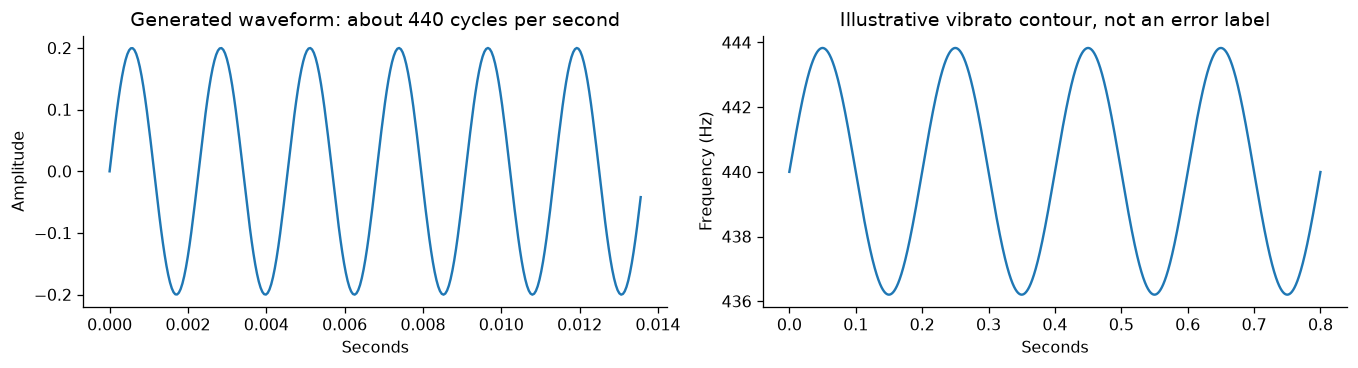

In [4]:
#  MUSIC-SHIFT-2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].plot(tone_times[:300], 0.2 * np.sin(2 * np.pi * original_hz * tone_times[:300]))
axes[0].set(xlabel='Seconds', ylabel='Amplitude', title='Generated waveform: about 440 cycles per second')
illustrative_contour = 440 * 2 ** (15 * np.sin(2 * np.pi * 5 * tone_times) / 1200)
axes[1].plot(tone_times, illustrative_contour)
axes[1].set(xlabel='Seconds', ylabel='Frequency (Hz)', title='Illustrative vibrato contour, not an error label')
plt.tight_layout()
plt.show()

 The frequency table and three players illustrate a known +20-cent shift and its inverse. The second plot illustrates vibrato. These are generated explanations, not learned repair results.